# Editabilidade dos marcadores nos experimentos com recortes e negativo

**Pergunta:** na tese, as perdas do marcador (Size, DMap) não servem para subir o Dice, e sim para dizer **o que é um marcador
bom para um humano editar**: pequeno, dentro do núcleo, com poucos componentes. Este notebook compara os modelos já treinados de
`recortes_negativo` (só Dice), `recortes_negativo_dmap` (Dice + DMap 0,1) e `recortes_negativo_bce` (Dice + BCE 1,0) pelos dois
critérios: a **segmentação** (Dice) e a **editabilidade do marcador** (componentes, fragmentos, buracos e como os componentes se
distribuem pelos núcleos), com e sem o **fechamento morfológico** do marcador.

- **Sem retreinar:** os modelos dos *folds* de cada experimento; cada imagem é prevista pelo modelo do *fold* em que ficou de
  fora, limiar 0,5. Os três experimentos têm a mesma configuração, menos as perdas (conferido abaixo).
- **Condições de segmentação**, para cada experimento: "como foi treinado" (faixa do negativo 3 px, sobreposição 1/4, sem TTA;
  tem de dar o Dice registrado), a **melhor inferência** (faixa 2 px, sobreposição 1/2, TTA) e a melhor inferência com
  **fechamento de 3 px**. As comparações são pareadas contra o `recortes_negativo` na mesma condição.
- **Editabilidade:** o marcador cru de cada experimento, cortado em τ, com fechamento de 0, 2 e 3 px.

**Tudo é mostrado no notebook**; salvar é opcional (`SALVAR_RESULTADOS`). Use um ambiente com **GPU** (~20 min numa T4).

## 0. Setup

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/Pedro-io/cell-fuzzy-seg.git"
BRANCH = "homolog"


def find_repo_root(start="."):
    p = os.path.abspath(start)
    prev = None
    while p != prev:
        if os.path.isdir(os.path.join(p, "src")) and os.path.exists(os.path.join(p, "pyproject.toml")):
            return p
        prev, p = p, os.path.dirname(p)
    return None


if "google.colab" in sys.modules:
    repo_root = os.path.join("/content", "cell-fuzzy-seg")
    if os.path.exists(repo_root):
        subprocess.run(["git", "-C", repo_root, "fetch", "origin", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "pull", "--ff-only", "origin", BRANCH], check=True)
    else:
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, repo_root], check=True)
else:
    repo_root = find_repo_root(os.getcwd())
    if repo_root is None:
        raise RuntimeError("Raiz do repositório não encontrada a partir do diretório atual.")

os.chdir(repo_root)
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
print("Repositório:", repo_root)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout.strip())

Repositório: /content/cell-fuzzy-seg
3b10c55 feat(exploracao): editabilidade dos marcadores nos experimentos e resultado do fechamento


In [2]:
if "google.colab" in sys.modules:
    get_ipython().system("python -m pip install -r requirements.txt -q")
else:
    print("Ambiente local: verifique se as dependências do requirements.txt estão instaladas.")

## 1. Configuração (comum aos experimentos)

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data.load.preprocessed_dataset import NEGATIVE_KEY, load_preprocessed
from src.evaluation.figures import pick_cases, prediction_figure
from src.evaluation.metrics import binary_metrics
from src.evaluation.report import save_run, summarize
from src.losses.loss_composer import LossComposer
from src.losses.terms import DiceTerm
from src.models.configs.marker_unet_config import UNET_CONFIG
from src.models.networks.final_segmentation.scribble_prompting_network import ScribblePromptingNetwork
from src.models.networks.marker_unet import MarkerUNet
from src.pipeline.steps.inference.frozen_segmentation_step import FrozenSegmentationStep
from src.pipeline.steps.inference.marker_step import MarkerStep
from src.pipeline.training_pipeline import TrainingPipeline
from src.pipeline.tiled_pipeline import TiledPipeline
from src.training.checkpoints import fold_name, load_pipeline
from src.training.kfold import TrainConfig, final_epochs, run_kfold

# Experimento cujos modelos são testados: a configuração abaixo precisa ser a dele (a célula seguinte confere).
# Configuração comum aos experimentos comparados (só as perdas mudam; a célula seguinte confere).
EXPERIMENT_NAME = "recortes_negativo"
OVERWRITE = False            # recusa gravar por cima de resultados ou modelos que já existem

RGBA_ALPHA = "mask"          # 4º canal da MarkerUNet: máscara do Cellpose ("prob": probabilidade)
TILE_SIZE = 256             # recorte do treino e bloco da avaliação (px da imagem original)
CROPS_PER_IMAGE = 4          # recortes sorteados de cada imagem por época
TILE_OVERLAP = 0.25          # sobreposição dos blocos na avaliação (fração do lado)
SP_INPUT_SIZE = (128, 128)   # entrada do ScribblePrompt (o recorte reduzido)
TAU = 0.5                    # limiar do canal positivo
NEGATIVE_RADIUS = 3              # None: sem negativo; n: negativo = pixels a mais de n px de qualquer máscara do Cellpose

CONFIG = TrainConfig(
    k=5, batch_size=16, max_epochs=200, patience=20, min_delta=0.0,
    lr=1e-4, grad_clip=1.0, threshold=0.5, seed=42, log_every=10,
    crop_size=TILE_SIZE, crops_per_image=CROPS_PER_IMAGE,
)
DESCRIPTION = {
    "perdas": "soft Dice (1,0), sem regularização do marcador",
    "rede_final": f"ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau={TAU}, input_size={SP_INPUT_SIZE}"
                  + ("" if NEGATIVE_RADIUS is None
                     else f", negativo = fundo do Cellpose (faixa livre de {NEGATIVE_RADIUS} px)"),
    "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
    "rgba_alpha": RGBA_ALPHA,
    "aumentacao": "rot90 + flips, sorteada a cada época",
    "recortes": f"treino com {CROPS_PER_IMAGE} recortes de {TILE_SIZE}² por imagem por época (MarkerUNet sem redução); avaliação da imagem inteira em blocos de {TILE_SIZE}² com sobreposição {TILE_OVERLAP} e janela de Hann",
}

assert torch.cuda.is_available() or "google.colab" not in sys.modules, "No Colab, use um ambiente com GPU."
print("Device:", CONFIG.device)
print(json.dumps(DESCRIPTION, indent=2, ensure_ascii=False))

Device: cuda
{
  "perdas": "soft Dice (1,0), sem regularização do marcador",
  "rede_final": "ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau=0.5, input_size=(128, 128), negativo = fundo do Cellpose (faixa livre de 3 px)",
  "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
  "rgba_alpha": "mask",
  "aumentacao": "rot90 + flips, sorteada a cada época",
  "recortes": "treino com 4 recortes de 256² por imagem por época (MarkerUNet sem redução); avaliação da imagem inteira em blocos de 256² com sobreposição 0.25 e janela de Hann"
}


In [4]:
import inspect

SALVAR_RESULTADOS = False    # True: grava as tabelas em docs/estudo/resultados/editabilidade_experimentos/
EXPERIMENTOS = ["recortes_negativo", "recortes_negativo_dmap", "recortes_negativo_bce"]
REFERENCIA_EXPERIMENTO = "recortes_negativo"
RAIO_FECHAMENTO = 3
RAIOS_EDITABILIDADE = [0, 2, 3]
# Melhor inferência sem retreinar (testes depois do treino 2)
RAIO_NEGATIVO_INFERENCIA = 2
SOBREPOSICAO_INFERENCIA = 0.5
TTA = True
IMAGENS_20X = {"TCGA-HE-7128-01Z-00-DX1", "TCGA-HE-7129-01Z-00-DX1", "TCGA-HE-7130-01Z-00-DX1"}

if "markers_key" not in inspect.signature(FrozenSegmentationStep.__init__).parameters:
    raise RuntimeError("O src/ carregado é anterior ao fechamento dos marcadores: reinicie a sessão do Colab e rode de novo.")
for exp in EXPERIMENTOS:
    with open(os.path.join("docs", "estudo", "resultados", exp, "config.json"), encoding="utf-8") as f:
        descricao = json.load(f)["descricao"]
    diferentes = sorted(k for k in set(descricao) | set(DESCRIPTION)
                        if k != "perdas" and descricao.get(k) != DESCRIPTION.get(k))
    if diferentes:
        raise ValueError(f"{exp} difere da configuração comum em {diferentes}; este notebook só compara as perdas.")
    print(f"{exp}: perdas = {descricao['perdas']}")

recortes_negativo: perdas = soft Dice (1,0), sem regularização do marcador
recortes_negativo_dmap: perdas = soft Dice (1,0) + DMap (0,1), mapa de distância por núcleo
recortes_negativo_bce: perdas = soft Dice (1,0) + BCE (1,0) sobre a segmentação final


## 2. Onde estão os modelos

In [5]:
# Modelos treinados: no Colab, no Google Drive de quem roda o notebook (sobrevive ao fim da sessão); fora dele,
# em ~/cell-fuzzy-models. Troque MODELS_ROOT para gravar em outro lugar.
if "google.colab" in sys.modules:
    try:
        from google.colab import drive

        drive.mount("/content/drive")
        MODELS_ROOT = "/content/drive/MyDrive/cell-fuzzy-models"
    except Exception as erro:
        print(f"Drive não montado ({erro}): os modelos ficam no disco da sessão e somem quando ela terminar.")
        MODELS_ROOT = "/content/cell-fuzzy-models"
else:
    MODELS_ROOT = os.path.expanduser(os.path.join("~", "cell-fuzzy-models"))
MODELS_DIR = os.path.join(MODELS_ROOT, EXPERIMENT_NAME)
print("Modelos em:", MODELS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelos em: /content/drive/MyDrive/cell-fuzzy-models/recortes_negativo


## 3. Dados de treino

In [6]:
train_samples = load_preprocessed("train", alpha=RGBA_ALPHA, negative_radius=NEGATIVE_RADIUS)
TRAIN_IDS = sorted(train_samples)
print(f"Treino: {len(train_samples)} imagens (o teste não é carregado neste notebook)")

d = [binary_metrics(s["cellpose_segmentation"] > 0, s["ground_truth"])["dice"] for s in train_samples.values()]
print(f"Cellpose sozinho, treino: Dice {np.mean(d):.4f} ± {np.std(d, ddof=1):.4f}")

Treino: 37 imagens (o teste não é carregado neste notebook)
Cellpose sozinho, treino: Dice 0.8450 ± 0.0302


## 4. Rede final e montagem do experimento

In [7]:
checkpoint = ScribblePromptingNetwork.download_checkpoint(os.path.join(MODELS_ROOT, "scribbleprompt"))
FINAL_NET = ScribblePromptingNetwork(
    checkpoint=checkpoint, device=CONFIG.device, scribble_mode="positive",
    positive_threshold=TAU, input_size=SP_INPUT_SIZE,
)


def factory():
    """Monta um experimento novo: MarkerUNet recém-inicializada, pipeline em blocos e perdas.

    O treino passa recortes de TILE_SIZE² (a MarkerUNet os vê sem redução); a avaliação passa a imagem
    inteira, que o TiledPipeline divide em blocos de TILE_SIZE² e cola de volta. O ScribblePrompt é
    congelado e não guarda estado, então a mesma instância serve a todos os folds.
    """
    marker_net = MarkerUNet(config=UNET_CONFIG)
    pipeline = TrainingPipeline([
        MarkerStep(model=marker_net, differentiable=True, target_size=TILE_SIZE, device=CONFIG.device),
        FrozenSegmentationStep(final_network=FINAL_NET, device=CONFIG.device,
                               negative_key=None if NEGATIVE_RADIUS is None else NEGATIVE_KEY),
    ])
    composer = LossComposer([DiceTerm()])
    return marker_net, TiledPipeline(pipeline, tile_size=TILE_SIZE, overlap=TILE_OVERLAP), composer

## 5. Modelos dos *folds* e funções

`com_fechamento` remonta o pipeline de um *fold* com o fechamento do marcador entre a MarkerUNet e o ScribblePrompt;
`marker_editability` (em `src/evaluation/editability.py`) mede o marcador cortado em τ.

In [8]:
import time

import pandas as pd
from scipy.stats import wilcoxon

from src.data.load.preprocessed_dataset import PreprocessedDataset, cellpose_negative, collate_samples
from src.evaluation.editability import marker_editability
from src.evaluation.report import provenance
from src.pipeline.steps.inference.marker_closing_step import MarkerClosingStep, grey_closing

FOLDS = {}
for exp in EXPERIMENTOS:
    FOLDS[exp] = []
    for k in range(CONFIG.k):
        pipeline, meta = load_pipeline(factory, os.path.join(MODELS_ROOT, exp), fold_name(k))
        FOLDS[exp].append((k, pipeline, meta["val_ids"]))
    print(exp, {k: len(ids) for k, _, ids in FOLDS[exp]}, "imagens de validação por fold")

AMOSTRAS = {i: {**s, NEGATIVE_KEY: cellpose_negative(s["cellpose_segmentation"], RAIO_NEGATIVO_INFERENCIA)}
            for i, s in train_samples.items()}


def com_fechamento(tiled, raio, overlap):
    """O pipeline do fold com o fechamento de raio `raio` antes do ScribblePrompt (raio 0: sem fechamento)."""
    passos = [tiled.pipeline.steps[0]]
    if raio > 0:
        passos.append(MarkerClosingStep(radius=raio))
    passos.append(FrozenSegmentationStep(final_network=FINAL_NET, device=CONFIG.device, negative_key=NEGATIVE_KEY,
                                         markers_key="markers_closed" if raio > 0 else "markers"))
    return TiledPipeline(TrainingPipeline(passos), tile_size=tiled.tile_size, overlap=overlap)


def lote(amostras, image_id):
    batch = collate_samples([PreprocessedDataset(amostras, ids=[image_id])[0]])
    return {c: (v.to(CONFIG.device) if torch.is_tensor(v) else v) for c, v in batch.items()}


def rodar(tiled, batch, tta):
    """Probabilidade (H, W) e marcador cru (H, W); com TTA, a probabilidade é a média das 8 rotações e espelhamentos."""
    with torch.no_grad():
        saida = tiled.run(batch, verbose=False)
        prob, marcador = saida["segmentation"], saida["markers"]
        if tta:
            for k in range(4):
                for espelhar in (False, True):
                    if k == 0 and not espelhar:
                        continue
                    def ida(x):
                        if not (torch.is_tensor(x) and x.ndim == 4):
                            return x
                        x = torch.rot90(x, k, dims=(-2, -1))
                        return torch.flip(x, dims=(-1,)) if espelhar else x
                    s = tiled.run({c: ida(v) for c, v in batch.items()}, verbose=False)["segmentation"]
                    if espelhar:
                        s = torch.flip(s, dims=(-1,))
                    prob = prob + torch.rot90(s, -k, dims=(-2, -1))
            prob = prob / 8
    return prob[0, 0].float().cpu().numpy(), marcador[0, 0].float().cpu().numpy()


def avaliar(exp, condicao, raio, amostras, overlap, tta):
    linhas, marcadores = [], {}
    for k, tiled, val_ids in FOLDS[exp]:
        tiled = com_fechamento(tiled, raio, overlap)
        for image_id in val_ids:
            prob, marcadores[image_id] = rodar(tiled, lote(amostras, image_id), tta)
            s = amostras[image_id]
            base = binary_metrics(s["cellpose_segmentation"] > 0, s["ground_truth"])
            linhas.append({"experimento": exp, "condicao": condicao, "id": image_id, "fold": k,
                           "aumento_20x": image_id in IMAGENS_20X, **binary_metrics(prob, s["ground_truth"]),
                           **{f"cellpose_{m}": v for m, v in base.items()}})
    return linhas, marcadores

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


recortes_negativo {0: 8, 1: 8, 2: 7, 3: 7, 4: 7} imagens de validação por fold
recortes_negativo_dmap {0: 8, 1: 8, 2: 7, 3: 7, 4: 7} imagens de validação por fold
recortes_negativo_bce {0: 8, 1: 8, 2: 7, 3: 7, 4: 7} imagens de validação por fold


## 6. Segmentação

In [9]:
inicio = time.time()
CONDICOES = [("como foi treinado", 0, train_samples, TILE_OVERLAP, False),
             ("melhor inferência", 0, AMOSTRAS, SOBREPOSICAO_INFERENCIA, TTA),
             (f"melhor inferência + fechamento {RAIO_FECHAMENTO} px", RAIO_FECHAMENTO, AMOSTRAS, SOBREPOSICAO_INFERENCIA, TTA)]
LINHAS, MARCADORES = [], {}
for exp in EXPERIMENTOS:
    for condicao, raio, amostras, overlap, tta in CONDICOES:
        linhas, marcadores = avaliar(exp, condicao, raio, amostras, overlap, tta)
        LINHAS += linhas
        if condicao == "melhor inferência":
            MARCADORES[exp] = marcadores
    print(f"{exp}: {(time.time() - inicio) / 60:.1f} min")
df = pd.DataFrame(LINHAS)

for exp in EXPERIMENTOS:
    registro = pd.read_csv(os.path.join("docs", "estudo", "resultados", exp, "folds.csv"))
    agora = df[(df.experimento == exp) & (df.condicao == "como foi treinado")].dice.mean()
    print(f"{exp}: Dice registrado {registro.dice.mean():.4f} | como foi treinado agora {agora:.4f}")
print(f"Cellpose: Dice {df[df.condicao == 'como foi treinado'].cellpose_dice.mean():.4f}")


def comparar(df):
    tabela = []
    for condicao in dict.fromkeys(df.condicao):
        ref = df[(df.experimento == REFERENCIA_EXPERIMENTO) & (df.condicao == condicao)].set_index("id")
        for exp in EXPERIMENTOS:
            s = df[(df.experimento == exp) & (df.condicao == condicao)].set_index("id").loc[ref.index]
            d = s.dice - ref.dice
            p = wilcoxon(s.dice, ref.dice).pvalue if (d != 0).any() else float("nan")
            tabela.append({"condição": condicao, "experimento": exp, "Dice": s.dice.mean(),
                           "precisão": s.precision.mean(), "revocação": s.recall.mean(), "massa": s.mass_ratio.mean(),
                           f"Δ {REFERENCIA_EXPERIMENTO}": d.mean(),
                           "melhora/piora": f"{int((d > 0).sum())}/{int((d < 0).sum())}", "p": p,
                           "acima do Cellpose": int((s.dice > s.cellpose_dice).sum()),
                           "Dice 20×": s[s.aumento_20x].dice.mean()})
    return pd.DataFrame(tabela)


pd.set_option("display.width", 240)
tabela = comparar(df)
tabela.round(4)

recortes_negativo: 7.5 min
recortes_negativo_dmap: 15.0 min
recortes_negativo_bce: 22.6 min
recortes_negativo: Dice registrado 0.8350 | como foi treinado agora 0.8350
recortes_negativo_dmap: Dice registrado 0.8302 | como foi treinado agora 0.8302
recortes_negativo_bce: Dice registrado 0.8335 | como foi treinado agora 0.8335
Cellpose: Dice 0.8450


,condição,experimento,Dice,precisão,revocação,massa,Δ recortes_negativo,melhora/piora,p,acima do Cellpose,Dice 20×
0,como foi treinado,recortes_negativo,0.8350,0.8116,0.8637,1.0695,0.0000,0/0,NaN,7,0.8095
1,como foi treinado,recortes_negativo_dmap,0.8302,0.8074,0.8582,1.0679,-0.0048,2/35,0.0000,2,0.8047
2,como foi treinado,recortes_negativo_bce,0.8335,0.8173,0.8536,1.0491,-0.0016,11/26,0.0083,6,0.8089
3,melhor inferência,recortes_negativo,0.8423,0.8395,0.8482,1.0142,0.0000,0/0,NaN,11,0.8266
4,melhor inferência,recortes_negativo_dmap,0.8381,0.8412,0.8380,0.9997,-0.0042,4/33,0.0000,2,0.8227
5,melhor inferência,recortes_negativo_bce,0.8404,0.8458,0.8379,0.9941,-0.0019,8/29,0.0001,9,0.8228
6,melhor inferência + fechamento 3 px,recortes_negativo,0.8416,0.8208,0.8667,1.0602,0.0000,0/0,NaN,10,0.8237
7,melhor inferência + fechamento 3 px,recortes_negativo_dmap,0.8384,0.8318,0.8479,1.0229,-0.0033,6/31,0.0000,7,0.8217
8,melhor inferência + fechamento 3 px,recortes_negativo_bce,0.8413,0.8306,0.8554,1.0338,-0.0003,14/23,0.3160,8,0.8231


### Como ler a tabela acima

- Cada bloco de três linhas é uma condição; dentro dele, os três experimentos. **Δ recortes_negativo, melhora/piora e p** comparam
  cada experimento com o `recortes_negativo` na **mesma** condição, imagem por imagem (Wilcoxon pareado).
- **como foi treinado:** conferência; cada experimento tem de reproduzir o seu Dice registrado (impresso acima da tabela).
- **melhor inferência** e **+ fechamento:** o que cada experimento rende com a inferência escolhida, sem e com o fechamento do
  marcador. Se o fechamento não mudar o Dice de um experimento, ele pode ser usado nele sem custo.

## 7. Editabilidade do marcador

O marcador cru de cada experimento (da condição "melhor inferência"), fechado na imagem inteira e cortado em τ. Médias por imagem
nas 37.

In [10]:
EDIT = []
for exp in EXPERIMENTOS:
    for image_id, marcador in MARCADORES[exp].items():
        gt = train_samples[image_id]["ground_truth"]
        for r in RAIOS_EDITABILIDADE:
            fechado = marcador if r == 0 else grey_closing(torch.from_numpy(marcador), r).numpy()
            area = float((fechado > TAU).mean())
            EDIT.append({"experimento": exp, "raio": r, "id": image_id, "area_marcador": area,
                         **marker_editability(fechado, gt, tau=TAU)})
edit = pd.DataFrame(EDIT)
resumo_edit = edit.drop(columns=["id"]).groupby(["experimento", "raio"], sort=False).mean()
resumo_edit.round(3)

area_marcador  componentes  fragmentos   buracos  regioes_sem_marcador  regioes_um_componente  regioes_partidas  componentes_unindo  componentes_fora
experimento            raio                                                                                                                                                       
recortes_negativo      0             0.142     2745.757    2027.514  1051.568                 0.019                  0.182             0.800              20.703           640.027
                       2             0.180      938.459     312.703   161.351                 0.019                  0.811             0.171              29.216           309.568
                       3             0.191      800.486     231.216    17.919                 0.019                  0.895             0.086              46.622           272.892
recortes_negativo_dmap 0             0.082     3309.459    2740.541   587.595                 0.080                  0.119             0.801              13.162           308.243
                       2             0.105     1228.243     647.351    37.243                 0.080                  0.479             0.441              17.676           130.000
                       3             0.118      821.054     279.676    18.811                 0.080                  0.664             0.256              22.595            89.351
recortes_negativo_bce  0             0.093     5298.189    4516.838   549.865                 0.016                  0.072             0.912              13.135          1025.243
                       2             0.126     1734.595    1008.162   188.757                 0.016                  0.415             0.569              21.946           475.649
                       3             0.152     1199.378     561.730   139.838                 0.016                  0.651             0.333              33.595           398.676

### Como ler a tabela acima

Uma linha por experimento e raio de fechamento (0 = marcador cru); médias por imagem.

- **area_marcador:** fração da imagem marcada (acima de τ). Um marcador menor é o objetivo do Size e do DMap da tese.
- **componentes, fragmentos (< 20 px), buracos:** quanto menos, mais limpo o marcador para quem vai editá-lo.
- **regioes_um_componente:** fração das regiões do GT com exatamente um componente de marcador ("um traço por núcleo").
  **regioes_partidas:** com dois ou mais. **regioes_sem_marcador:** sem nenhum (um marcador pequeno demais aparece aqui).
- **componentes_unindo:** componentes que tocam duas ou mais regiões do GT (marcador atravessando núcleos vizinhos).
  **componentes_fora:** componentes que não tocam o GT.

Um experimento é melhor para edição se tiver mais regiões com um componente, menos fragmentos, buracos e uniões, **sem perder Dice**
na tabela da seção 6.

## 8. Figura: marcadores dos três experimentos na mesma região

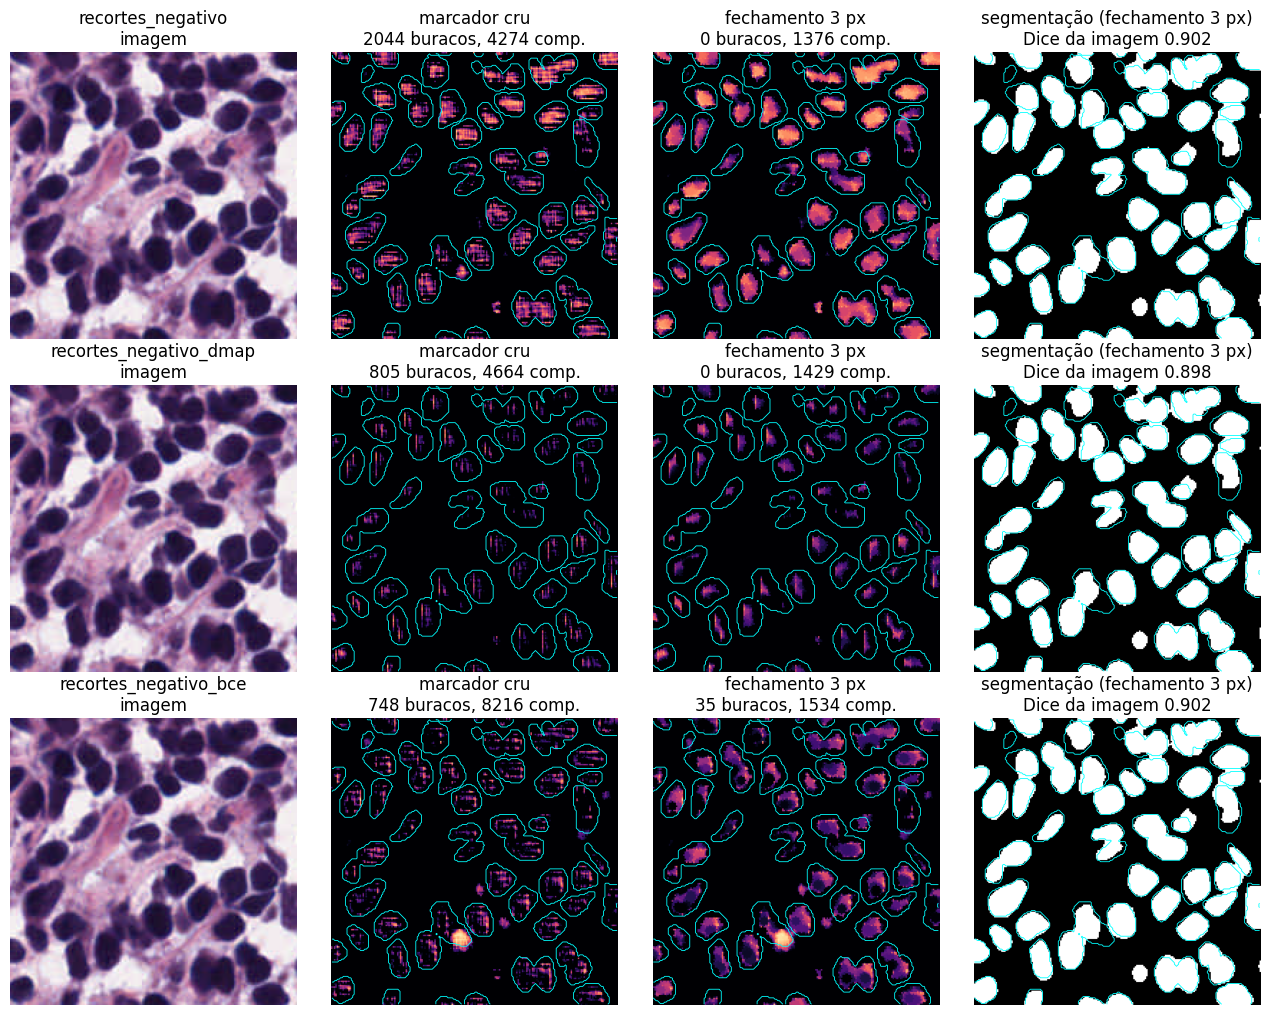

In [11]:
FIG_ID = "TCGA-KB-A93J-01A-01-TS1" if "TCGA-KB-A93J-01A-01-TS1" in train_samples else sorted(train_samples)[0]
LADO, Y0, X0 = 200, 400, 400
janela = (slice(Y0, Y0 + LADO), slice(X0, X0 + LADO))
s = train_samples[FIG_ID]
gt = s["ground_truth"][janela] > 0

fig, eixos = plt.subplots(len(EXPERIMENTOS), 4, figsize=(13, 3.4 * len(EXPERIMENTOS)))
for i, exp in enumerate(EXPERIMENTOS):
    marcador = MARCADORES[exp][FIG_ID]
    fechado = grey_closing(torch.from_numpy(marcador), RAIO_FECHAMENTO).numpy()
    k, tiled, _ = next(f for f in FOLDS[exp] if FIG_ID in f[2])
    prob, _ = rodar(com_fechamento(tiled, RAIO_FECHAMENTO, SOBREPOSICAO_INFERENCIA), lote(AMOSTRAS, FIG_ID), TTA)
    eixos[i, 0].imshow(s["image"][janela])
    eixos[i, 0].set_title(f"{exp}\nimagem")
    for j, (m, nome) in enumerate([(marcador, "marcador cru"), (fechado, f"fechamento {RAIO_FECHAMENTO} px")], start=1):
        e = marker_editability(m, s["ground_truth"], tau=TAU)
        eixos[i, j].imshow(np.clip((m[janela] - TAU) / (1 - TAU), 0, 1), cmap="magma", vmin=0, vmax=1)
        eixos[i, j].contour(gt, levels=[0.5], colors="cyan", linewidths=0.6)
        eixos[i, j].set_title(f"{nome}\n{e['buracos']} buracos, {e['componentes']} comp.")
    eixos[i, 3].imshow(prob[janela] > 0.5, cmap="gray")
    eixos[i, 3].contour(gt, levels=[0.5], colors="cyan", linewidths=0.6)
    eixos[i, 3].set_title(f"segmentação (fechamento {RAIO_FECHAMENTO} px)\nDice da imagem "
                          f"{binary_metrics(prob, s['ground_truth'])['dice']:.3f}")
for eixo in eixos.ravel():
    eixo.axis("off")
plt.tight_layout()
plt.show()

### Como ler a figura acima

Uma linha por experimento, todas na **mesma região** (200 × 200 px) da mesma imagem, prevista pelo modelo do *fold* em que ela
ficou de fora.

- **marcador cru** e **com fechamento:** o marcador cortado em τ (o scribble que o ScribblePrompt recebe), em escala fixa de
  0 (preto) a 1 (amarelo claro), com o contorno do GT em ciano. O título conta buracos e componentes da imagem inteira.
- **segmentação:** a saída final (probabilidade > 0,5) com o fechamento, e o Dice da imagem inteira.

O que procurar: qual experimento dá o marcador mais próximo de "uma mancha por núcleo, dentro do núcleo", e se a segmentação muda.

## 9. Salvar (opcional)

In [12]:
if SALVAR_RESULTADOS:
    pasta = os.path.join("docs", "estudo", "resultados", "editabilidade_experimentos")
    os.makedirs(pasta, exist_ok=False)
    df.to_csv(os.path.join(pasta, "por_imagem.csv"), index=False)
    tabela.to_csv(os.path.join(pasta, "resumo.csv"), index=False)
    edit.to_csv(os.path.join(pasta, "editabilidade_por_imagem.csv"), index=False)
    resumo_edit.to_csv(os.path.join(pasta, "editabilidade_resumo.csv"))
    with open(os.path.join(pasta, "config.json"), "w", encoding="utf-8") as f:
        json.dump({"experimentos": EXPERIMENTOS, "raio_fechamento": RAIO_FECHAMENTO, "raios_editabilidade": RAIOS_EDITABILIDADE,
                   "raio_negativo_inferencia": RAIO_NEGATIVO_INFERENCIA, "sobreposicao_inferencia": SOBREPOSICAO_INFERENCIA,
                   "tta": TTA, "procedencia": provenance()}, f, indent=2, ensure_ascii=False)
    print("Resultados em:", pasta)
else:
    print("Nada salvo (SALVAR_RESULTADOS = False).")

Nada salvo (SALVAR_RESULTADOS = False).
